# Cipher-Type Diagnostic Tests

## Motivation
All 16 previous decipherment models assumed **monoalphabetic substitution** (or positional
variants). The structural ceiling (68% n-gram, 3 roots) could indicate a fundamentally
different cipher type. This notebook applies four classical cryptanalytic diagnostics:

1. **Index of Coincidence (IC)** — distinguishes natural language from polyalphabetic encryption
2. **Kasiski Examination** — detects repeating-key periodicity (Vigenère-type)
3. **Bigram Entropy Analysis** — detects digraphic/polygraphic ciphers (Playfair, Hill)
4. **Transposition Test** — checks if glyph reordering improves statistical fit

## Expected Outcomes
| Cipher type | IC | Kasiski | Bigram entropy | Transposition |
|-------------|-----|---------|----------------|---------------|
| Natural language | High (~0.065) | No pattern | Structured | No improvement |
| Monoalphabetic | High (same) | No pattern | Structured | No improvement |
| Polyalphabetic | Low (~1/|Σ|) | Clear period | Flatter | No improvement |
| Polygraphic | High | No pattern | Anomalous pairs | No improvement |
| Transposition | High | No pattern | Disrupted | Improvement |
| Nomenclator | Mixed | Partial | Mixed | No improvement |

In [1]:
import re, math, random
from collections import Counter, defaultdict
from itertools import product as iproduct
import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path

plt.rcParams.update({'figure.dpi': 120, 'font.size': 10})
random.seed(42)
np.random.seed(42)

# ── Parser STA1 2.0 ──
def parsear_sta_completo(filepath):
    tokens = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', linea):
                continue
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            texto = match.group(1).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>', '', texto)
            texto = re.sub(r'-', '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    tokens.extend(glifos)
                    tokens.append('.')
    return tokens

def tokens_a_palabras(tokens):
    palabras, actual = [], []
    for t in tokens:
        if t == '.':
            if actual:
                palabras.append(actual)
                actual = []
        else:
            actual.append(t)
    if actual:
        palabras.append(actual)
    return palabras

# Load corpus
STA_PATH = 'corpus/voynich_sta.txt'
tokens = parsear_sta_completo(STA_PATH)
palabras = tokens_a_palabras(tokens)
corpus_plano = [t for t in tokens if t != '.']
VOCAB = sorted(set(corpus_plano))

print(f"Glyphs: {len(corpus_plano):,}")
print(f"Words:  {len(palabras):,}")
print(f"Vocab:  {len(VOCAB)} types")
print(f"Mean word length: {np.mean([len(w) for w in words]):.2f} glyphs")

Glyphs: 157,254
Words:  37,087
Vocab:  166 types
Mean word length: 4.24 glyphs


## Test 1: Index of Coincidence (IC)

The IC measures how likely two randomly chosen elements from a text are the same symbol.

- **Natural language / monoalphabetic substitution**: IC ≈ IC of the underlying language
- **Polyalphabetic (long key)**: IC → 1/|Σ| (flat distribution)
- **Homophonic**: IC < natural language (more spread)

For an alphabet of size |Σ|=166, random IC = 1/166 ≈ 0.00602.

We also compute IC in **sliding windows** to detect local periodicity, and compare with
reference corpora (Latin, Hebrew, shuffled Voynich).

=== INDEX OF COINCIDENCE ===
Voynich global IC:     0.076391
Random expectation:    0.006024  (1/166)
Shuffled control:      0.076391  (should ≈ global)
IC ratio (obs/random): 12.68x

By position:
  Onset IC:   0.119246  (N=37,087)
  Middle IC:  0.104192  (N=83,963)
  Coda IC:    0.222645  (N=36,204)

Positional (glyph,pos) IC: 0.048137

=== Reference ICs ===
  English (26)             : 0.066700
  Latin (26)               : 0.077000
  Random (26)              : 0.038462
  Random (166)             : 0.006024
  Voynich (166 types)      : 0.076391

=== INTERPRETATION ===
IC is WELL ABOVE random → INCONSISTENT with polyalphabetic cipher
The text has strong frequency structure (like natural language or mono substitution)


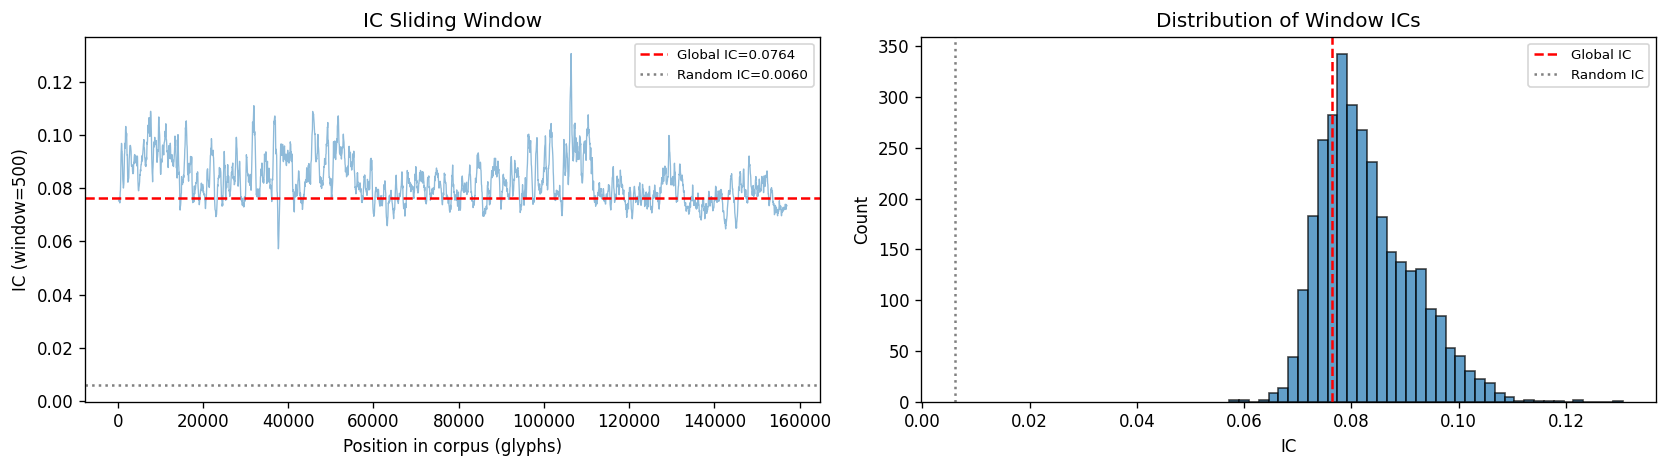

Saved: images/cipher_ic_analysis.png


In [2]:
def index_of_coincidence(sequence):
    """Compute IC = sum(f_i * (f_i - 1)) / (N * (N - 1))."""
    freq = Counter(sequence)
    N = len(sequence)
    if N < 2:
        return 0.0
    return sum(f * (f - 1) for f in freq.values()) / (N * (N - 1))

def ic_windows(sequence, window_size=500, step=100):
    """Compute IC in sliding windows across the text."""
    positions, ics = [], []
    for i in range(0, len(sequence) - window_size, step):
        window = sequence[i:i + window_size]
        positions.append(i + window_size // 2)
        ics.append(index_of_coincidence(window))
    return positions, ics

# ── Global IC ──
ic_voynich = index_of_coincidence(corpus_plano)
ic_random = 1.0 / len(VOCAB)

# Shuffled null (same frequencies, random order — should give same IC)
shuffled = corpus_plano.copy()
random.shuffle(shuffled)
ic_shuffled = index_of_coincidence(shuffled)

# IC of word-position stream (onset, middle, coda)
pos_stream = []
for w in palabras:
    for i, g in enumerate(w):
        if i == 0:
            pos_stream.append(('O', g))
        elif i == len(w) - 1:
            pos_stream.append(('C', g))
        else:
            pos_stream.append(('M', g))
ic_positional = index_of_coincidence(pos_stream)

# IC per position
onset_glyphs = [w[0] for w in palabras if len(w) >= 1]
coda_glyphs = [w[-1] for w in palabras if len(w) >= 2]
middle_glyphs = [g for w in palabras for g in w[1:-1] if len(w) >= 3]

ic_onset = index_of_coincidence(onset_glyphs)
ic_coda = index_of_coincidence(coda_glyphs)
ic_middle = index_of_coincidence(middle_glyphs)

print("=== INDEX OF COINCIDENCE ===")
print(f"Voynich global IC:     {ic_voynich:.6f}")
print(f"Random expectation:    {ic_random:.6f}  (1/{len(VOCAB)})")
print(f"Shuffled control:      {ic_shuffled:.6f}  (should ≈ global)")
print(f"IC ratio (obs/random): {ic_voynich / ic_random:.2f}x")
print(f"\nBy position:")
print(f"  Onset IC:   {ic_onset:.6f}  (N={len(onset_glyphs):,})")
print(f"  Middle IC:  {ic_middle:.6f}  (N={len(middle_glyphs):,})")
print(f"  Coda IC:    {ic_coda:.6f}  (N={len(coda_glyphs):,})")
print(f"\nPositional (glyph,pos) IC: {ic_positional:.6f}")

# ── Reference: natural language ICs ──
# Well-known values for 26-letter languages (letters only)
ref_ics = {
    'English (26)': 0.0667,
    'Latin (26)': 0.0770,
    'Random (26)': 1/26,
    'Random (166)': 1/166,
    'Voynich (166 types)': ic_voynich,
}

print(f"\n=== Reference ICs ===")
for name, val in ref_ics.items():
    print(f"  {name:25s}: {val:.6f}")

# Interpretation
print(f"\n=== INTERPRETATION ===")
if ic_voynich > 3 * ic_random:
    print("IC is WELL ABOVE random → INCONSISTENT with polyalphabetic cipher")
    print("The text has strong frequency structure (like natural language or mono substitution)")
else:
    print("IC is close to random → CONSISTENT with polyalphabetic cipher")

# ── Sliding window IC ──
positions, ics = ic_windows(corpus_plano, window_size=500, step=50)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: IC across text
axes[0].plot(positions, ics, alpha=0.5, lw=0.8)
axes[0].axhline(ic_voynich, color='red', ls='--', label=f'Global IC={ic_voynich:.4f}')
axes[0].axhline(ic_random, color='gray', ls=':', label=f'Random IC={ic_random:.4f}')
axes[0].set_xlabel('Position in corpus (glyphs)')
axes[0].set_ylabel('IC (window=500)')
axes[0].set_title('IC Sliding Window')
axes[0].legend(fontsize=8)

# Right: histogram of window ICs
axes[1].hist(ics, bins=40, edgecolor='black', alpha=0.7)
axes[1].axvline(ic_voynich, color='red', ls='--', label='Global IC')
axes[1].axvline(ic_random, color='gray', ls=':', label='Random IC')
axes[1].set_xlabel('IC')
axes[1].set_ylabel('Count')
axes[1].set_title('Distribution of Window ICs')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig('images/cipher_ic_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: images/cipher_ic_analysis.png")

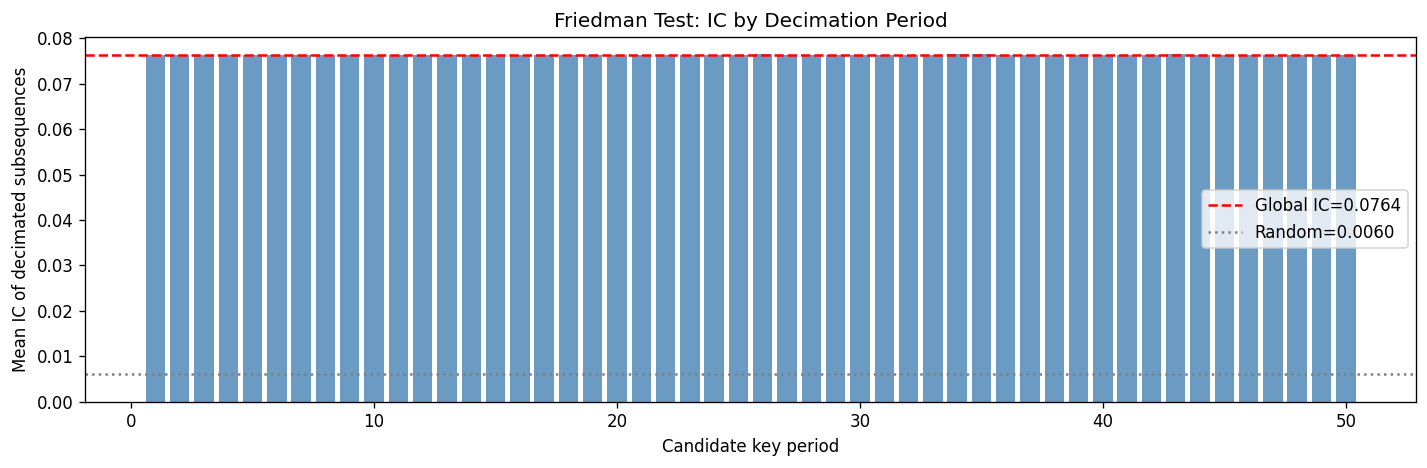

Saved: images/cipher_friedman_test.png

Baseline IC (periods 1-5): 0.076396
Threshold (2σ above): 0.076425
Peaks above threshold: [(34, np.float64(0.07644708973875777))]
→ Possible key period detected!


In [3]:
# ── IC by decimation (Friedman test for key length) ──
# For a Vigenère with key length k, taking every k-th element should yield higher IC

def ic_by_decimation(sequence, max_period=30):
    """For each candidate period k, split text into k subsequences
    (positions 0,k,2k,... / 1,k+1,2k+1,... etc.), compute mean IC."""
    results = []
    for k in range(1, max_period + 1):
        subsequences = [[] for _ in range(k)]
        for i, sym in enumerate(sequence):
            subsequences[i % k].append(sym)
        # Mean IC of the k subsequences
        ics = [index_of_coincidence(sub) for sub in subsequences if len(sub) > 1]
        results.append((k, np.mean(ics) if ics else 0))
    return results

decimation_results = ic_by_decimation(corpus_plano, max_period=50)
periods = [r[0] for r in decimation_results]
mean_ics = [r[1] for r in decimation_results]

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(periods, mean_ics, color='steelblue', alpha=0.8)
ax.axhline(ic_voynich, color='red', ls='--', label=f'Global IC={ic_voynich:.4f}')
ax.axhline(ic_random, color='gray', ls=':', label=f'Random={ic_random:.4f}')
ax.set_xlabel('Candidate key period')
ax.set_ylabel('Mean IC of decimated subsequences')
ax.set_title('Friedman Test: IC by Decimation Period')
ax.legend()
plt.tight_layout()
plt.savefig('images/cipher_friedman_test.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: images/cipher_friedman_test.png")

# Check for peaks
baseline = np.mean(mean_ics[:5])
threshold = baseline + 2 * np.std(mean_ics)
peaks = [(p, ic) for p, ic in decimation_results if ic > threshold and p > 1]

print(f"\nBaseline IC (periods 1-5): {baseline:.6f}")
print(f"Threshold (2σ above): {threshold:.6f}")
if peaks:
    print(f"Peaks above threshold: {peaks}")
    print("→ Possible key period detected!")
else:
    print("No peaks above threshold → NO evidence of periodic key")

## Test 2: Kasiski Examination

The Kasiski test looks for **repeated sequences** (n-grams of glyphs) and measures the
**distances** between repetitions. For a Vigenère cipher, these distances tend to be
multiples of the key length.

We search for repeated trigrams and longer sequences, compute distance GCDs, and
check whether any key length dominates.

=== KASISKI EXAMINATION ===

  3-grams: 3,882 distinct repeated, 153,858 total occurrences
  4-grams: 10,237 distinct repeated, 144,268 total occurrences
  5-grams: 17,277 distinct repeated, 122,623 total occurrences
  6-grams: 19,805 distinct repeated, 89,804 total occurrences
  7-grams: 15,456 distinct repeated, 55,403 total occurrences
  8-grams: 9,476 distinct repeated, 30,413 total occurrences

Distances computed: 42,416,915 (3-gram), 11,753,896 (4-gram), 3,328,860 (5-gram)

=== Factor analysis (3-grams, top 15) ===
Factor    Count   Fraction   Expected    Ratio
     2 21,202,487     0.4999     0.5000     1.00x
     3 14,135,888     0.3333     0.3333     1.00x
     4 10,601,737     0.2499     0.2500     1.00x
     5 8,483,542     0.2000     0.2000     1.00x
     6 7,066,274     0.1666     0.1667     1.00x
     7 6,058,828     0.1428     0.1429     1.00x
     8 5,298,159     0.1249     0.1250     1.00x
     9 4,714,256     0.1111     0.1111     1.00x
    10 4,237,229     0.0999    

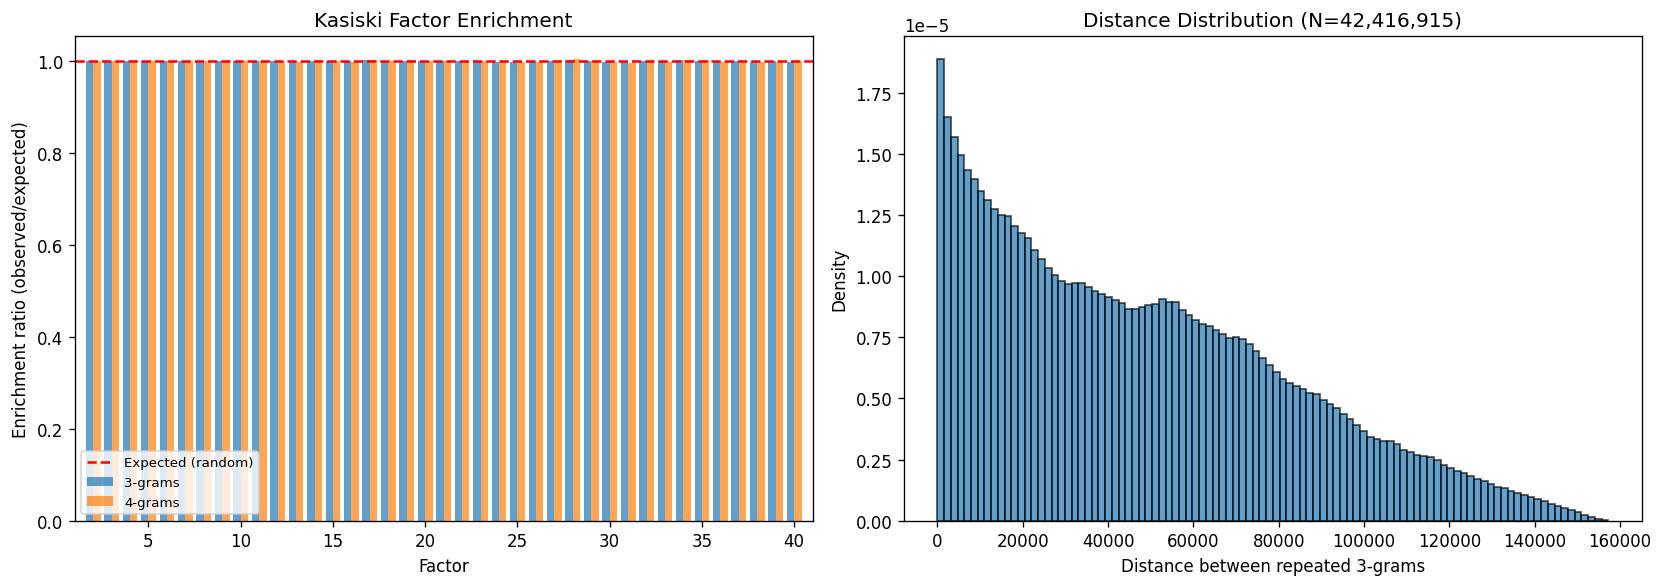

Saved: images/cipher_kasiski.png

=== INTERPRETATION ===
Max enrichment: 1.00x (all factors ≤ 1.5x)
→ NO evidence of repeating key periodicity
→ INCONSISTENT with Vigenère-type polyalphabetic cipher


In [4]:
from math import gcd
from functools import reduce

def kasiski_examination(sequence, min_ngram=3, max_ngram=8):
    """Find repeated n-grams and their positions."""
    results = {}

    for n in range(min_ngram, max_ngram + 1):
        ngram_positions = defaultdict(list)
        for i in range(len(sequence) - n + 1):
            ngram = tuple(sequence[i:i + n])
            ngram_positions[ngram].append(i)

        # Keep only repeated n-grams
        repeated = {ng: pos for ng, pos in ngram_positions.items() if len(pos) >= 2}
        results[n] = repeated

    return results

def compute_distances(ngram_positions):
    """Compute all pairwise distances for repeated n-grams."""
    all_distances = []
    for ngram, positions in ngram_positions.items():
        for i in range(len(positions)):
            for j in range(i + 1, len(positions)):
                all_distances.append(positions[j] - positions[i])
    return all_distances

def factor_distances(distances, max_factor=50):
    """Count how many distances are divisible by each factor."""
    factor_counts = Counter()
    for d in distances:
        for f in range(2, max_factor + 1):
            if d % f == 0:
                factor_counts[f] += 1
    return factor_counts

# ── Run Kasiski ──
kasiski_results = kasiski_examination(corpus_plano, min_ngram=3, max_ngram=8)

print("=== KASISKI EXAMINATION ===\n")

# Summary per n-gram length
for n in range(3, 9):
    repeated = kasiski_results[n]
    total_reps = sum(len(pos) for pos in repeated.values())
    print(f"  {n}-grams: {len(repeated):,} distinct repeated, {total_reps:,} total occurrences")

# Distance analysis for trigrams (most data)
distances_3 = compute_distances(kasiski_results[3])
distances_4 = compute_distances(kasiski_results[4])
distances_5 = compute_distances(kasiski_results[5])

print(f"\nDistances computed: {len(distances_3):,} (3-gram), {len(distances_4):,} (4-gram), {len(distances_5):,} (5-gram)")

# Factor analysis
factors_3 = factor_distances(distances_3, max_factor=50)
factors_4 = factor_distances(distances_4, max_factor=50)

# Normalize by total distances to get fraction divisible
total_d3 = len(distances_3)
total_d4 = len(distances_4)

print(f"\n=== Factor analysis (3-grams, top 15) ===")
print(f"{'Factor':>6} {'Count':>8} {'Fraction':>10} {'Expected':>10} {'Ratio':>8}")
for f, count in factors_3.most_common(15):
    expected_frac = 1.0 / f  # fraction of integers divisible by f
    observed_frac = count / total_d3
    ratio = observed_frac / expected_frac
    print(f"{f:6d} {count:8,} {observed_frac:10.4f} {expected_frac:10.4f} {ratio:8.2f}x")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: factor enrichment for trigrams
factors = list(range(2, 41))
enrichments_3 = []
enrichments_4 = []
for f in factors:
    expected = 1.0 / f
    obs_3 = factors_3.get(f, 0) / total_d3 if total_d3 else 0
    obs_4 = factors_4.get(f, 0) / total_d4 if total_d4 else 0
    enrichments_3.append(obs_3 / expected if expected else 0)
    enrichments_4.append(obs_4 / expected if expected else 0)

axes[0].bar(np.array(factors) - 0.2, enrichments_3, width=0.4, alpha=0.7, label='3-grams')
axes[0].bar(np.array(factors) + 0.2, enrichments_4, width=0.4, alpha=0.7, label='4-grams')
axes[0].axhline(1.0, color='red', ls='--', label='Expected (random)')
axes[0].set_xlabel('Factor')
axes[0].set_ylabel('Enrichment ratio (observed/expected)')
axes[0].set_title('Kasiski Factor Enrichment')
axes[0].legend(fontsize=8)
axes[0].set_xlim(1, 41)

# Right: distance histogram (trigrams)
axes[1].hist(distances_3, bins=100, edgecolor='black', alpha=0.7, density=True)
axes[1].set_xlabel('Distance between repeated 3-grams')
axes[1].set_ylabel('Density')
axes[1].set_title(f'Distance Distribution (N={len(distances_3):,})')

plt.tight_layout()
plt.savefig('images/cipher_kasiski.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: images/cipher_kasiski.png")

# ── Interpretation ──
print(f"\n=== INTERPRETATION ===")
# Check if any factor stands out (enrichment > 1.5)
strong_factors = [(f, e) for f, e in zip(factors, enrichments_3) if e > 1.5]
if strong_factors:
    print(f"Strong factor enrichment detected: {strong_factors}")
    print("→ Possible periodic key!")
else:
    max_enrich = max(enrichments_3)
    print(f"Max enrichment: {max_enrich:.2f}x (all factors ≤ 1.5x)")
    print("→ NO evidence of repeating key periodicity")
    print("→ INCONSISTENT with Vigenère-type polyalphabetic cipher")

## Test 3: Bigram Entropy Analysis

Polygraphic ciphers (Playfair, Hill) encrypt pairs or blocks of letters together.
This creates distinctive **bigram patterns**: certain pairs become much more or less
common than expected from individual frequencies.

We compare:
- **Observed bigram entropy** H(X,Y) with **independent model** H(X)+H(Y)
- **Mutual information** MI(X;Y) = H(X)+H(Y) - H(X,Y) — how much one glyph predicts the next
- Comparison with shuffled text (null) and real languages

=== BIGRAM ENTROPY ANALYSIS ===
Unigram entropy H(X):        4.1408 bits
Bigram entropy H(X,Y):       7.0295 bits
Independent model 2·H(X):    8.2817 bits
Mutual information MI(X;Y):  1.2522 bits
Normalized MI:               0.3024
Redundancy: 15.1%

Null MI (shuffled): 0.0190 ± 0.0003
Z-score: 3831.2

Bigram chi² statistic: 1082143
Degrees of freedom: 27,225
Chi²/df ratio: 39.75

Top 10 OVER-represented bigrams (obs/expected ratio):
      Bigram    Obs      Exp   Ratio
  A3-F1   1673    158.1   10.58x
  A3-F3    608     57.6   10.55x
  A3-G1   3905    385.0   10.14x
  A3-F2     74      7.5    9.88x
  A3-E2    121     12.7    9.55x
  A3-E1    147     16.4    8.98x
  A3-G3    141     16.3    8.66x
  Lb-J1    223     26.4    8.46x
  M1-C2     63      7.8    8.10x
  A3-B3    779     98.5    7.91x

Top 10 UNDER-represented bigrams (should appear but rare):
  A2-G1      1    462.2   0.002x
  A3-K2      1    410.9   0.002x
  K1-D1      1    381.8   0.003x
  D1-B1      1    362.0   0.003x
  K

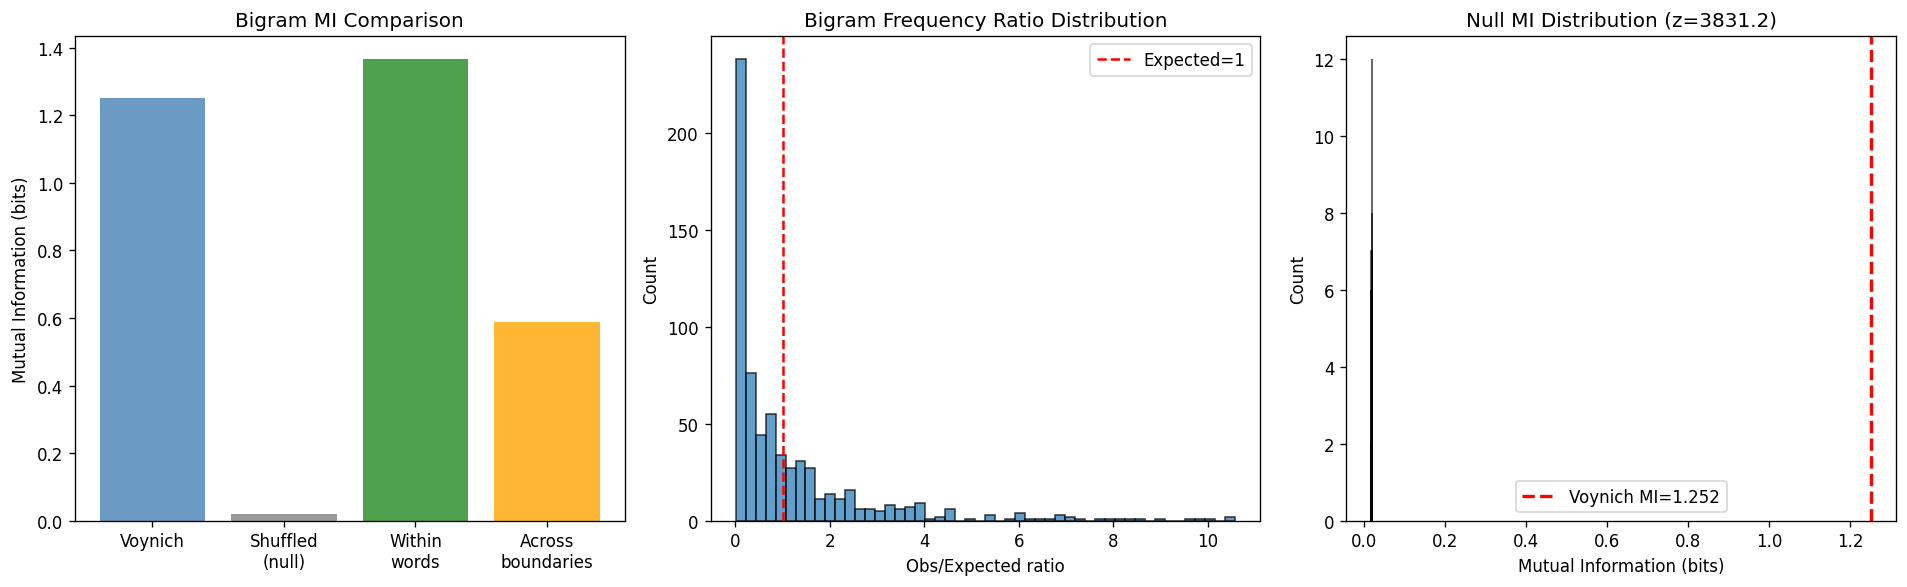

Saved: images/cipher_bigram_entropy.png

=== INTERPRETATION ===
Normalized MI = 0.302 — STRONG bigram structure
→ INCONSISTENT with polygraphic cipher (Playfair would disrupt natural bigram patterns)
→ Consistent with natural language or monoalphabetic substitution


In [5]:
def unigram_entropy(sequence):
    freq = Counter(sequence)
    N = len(sequence)
    return -sum((c/N) * math.log2(c/N) for c in freq.values())

def bigram_entropy(sequence):
    """Joint entropy H(X_i, X_{i+1}) of consecutive pairs."""
    bigrams = [(sequence[i], sequence[i+1]) for i in range(len(sequence)-1)]
    freq = Counter(bigrams)
    N = len(bigrams)
    return -sum((c/N) * math.log2(c/N) for c in freq.values())

def bigram_mutual_information(sequence):
    """MI(X_i; X_{i+1}) = H(X) + H(X) - H(X,X+1)."""
    H1 = unigram_entropy(sequence)
    H2 = bigram_entropy(sequence)
    return 2 * H1 - H2  # MI = H(X) + H(Y) - H(X,Y), with H(X)≈H(Y)

# ── Compute for Voynich ──
H1_voynich = unigram_entropy(corpus_plano)
H2_voynich = bigram_entropy(corpus_plano)
MI_voynich = 2 * H1_voynich - H2_voynich
MI_norm = MI_voynich / H1_voynich  # Normalized MI (0=independent, 1=deterministic)

print("=== BIGRAM ENTROPY ANALYSIS ===")
print(f"Unigram entropy H(X):        {H1_voynich:.4f} bits")
print(f"Bigram entropy H(X,Y):       {H2_voynich:.4f} bits")
print(f"Independent model 2·H(X):    {2*H1_voynich:.4f} bits")
print(f"Mutual information MI(X;Y):  {MI_voynich:.4f} bits")
print(f"Normalized MI:               {MI_norm:.4f}")
print(f"Redundancy: {100*(2*H1_voynich - H2_voynich)/(2*H1_voynich):.1f}%")

# ── Null: shuffled (breaks bigram structure) ──
N_NULL = 100
mi_null = []
for _ in range(N_NULL):
    shuf = corpus_plano.copy()
    random.shuffle(shuf)
    mi_null.append(bigram_mutual_information(shuf))

mi_null_mean = np.mean(mi_null)
mi_null_std = np.std(mi_null)
mi_z = (MI_voynich - mi_null_mean) / mi_null_std

print(f"\nNull MI (shuffled): {mi_null_mean:.4f} ± {mi_null_std:.4f}")
print(f"Z-score: {mi_z:.1f}")

# ── Bigram frequency analysis ──
# Top and bottom bigrams vs expected
bigrams_obs = Counter()
for i in range(len(corpus_plano) - 1):
    bigrams_obs[(corpus_plano[i], corpus_plano[i+1])] += 1

N_bigrams = sum(bigrams_obs.values())
unigram_freq = Counter(corpus_plano)
N_uni = len(corpus_plano)

# Compute chi-squared-like statistic for independence
chi2_vals = []
for (g1, g2), obs in bigrams_obs.items():
    expected = (unigram_freq[g1] / N_uni) * (unigram_freq[g2] / N_uni) * N_bigrams
    if expected > 0:
        chi2_vals.append(((obs - expected)**2) / expected)

chi2_total = sum(chi2_vals)
df_approx = (len(VOCAB) - 1) ** 2
chi2_ratio = chi2_total / df_approx

print(f"\nBigram chi² statistic: {chi2_total:.0f}")
print(f"Degrees of freedom: {df_approx:,}")
print(f"Chi²/df ratio: {chi2_ratio:.2f}")

# Top over-represented bigrams
bigram_ratios = []
for (g1, g2), obs in bigrams_obs.items():
    expected = (unigram_freq[g1] / N_uni) * (unigram_freq[g2] / N_uni) * N_bigrams
    if expected > 5:  # only well-estimated
        bigram_ratios.append(((g1, g2), obs, expected, obs/expected))

bigram_ratios.sort(key=lambda x: -x[3])

print(f"\nTop 10 OVER-represented bigrams (obs/expected ratio):")
print(f"{'Bigram':>12} {'Obs':>6} {'Exp':>8} {'Ratio':>7}")
for bg, obs, exp, ratio in bigram_ratios[:10]:
    print(f"  {bg[0]}-{bg[1]:>2} {obs:6d} {exp:8.1f} {ratio:7.2f}x")

print(f"\nTop 10 UNDER-represented bigrams (should appear but rare):")
bigram_ratios.sort(key=lambda x: x[3])
for bg, obs, exp, ratio in bigram_ratios[:10]:
    print(f"  {bg[0]}-{bg[1]:>2} {obs:6d} {exp:8.1f} {ratio:7.3f}x")

# ── Bigram MI within words vs across word boundaries ──
within_bigrams = []
for w in palabras:
    for i in range(len(w)-1):
        within_bigrams.append((w[i], w[i+1]))

across_bigrams = []
for i in range(len(palabras)-1):
    if palabras[i] and palabras[i+1]:
        across_bigrams.append((palabras[i][-1], palabras[i+1][0]))

mi_within = bigram_mutual_information([g for pair in within_bigrams for g in pair])
mi_across = bigram_mutual_information([g for pair in across_bigrams for g in pair])

print(f"\nMI within words:  {mi_within:.4f} bits")
print(f"MI across boundaries: {mi_across:.4f} bits")
print(f"Ratio within/across: {mi_within/mi_across:.2f}x")

# ── Visualization ──
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Left: MI comparison
categories = ['Voynich', 'Shuffled\n(null)', 'Within\nwords', 'Across\nboundaries']
mi_values = [MI_voynich, mi_null_mean, mi_within, mi_across]
colors = ['steelblue', 'gray', 'forestgreen', 'orange']
axes[0].bar(categories, mi_values, color=colors, alpha=0.8)
axes[0].set_ylabel('Mutual Information (bits)')
axes[0].set_title('Bigram MI Comparison')

# Middle: obs/expected ratio distribution
ratios_only = [r[3] for r in bigram_ratios if r[2] > 5]
axes[1].hist(ratios_only, bins=50, edgecolor='black', alpha=0.7)
axes[1].axvline(1.0, color='red', ls='--', label='Expected=1')
axes[1].set_xlabel('Obs/Expected ratio')
axes[1].set_ylabel('Count')
axes[1].set_title('Bigram Frequency Ratio Distribution')
axes[1].legend()

# Right: null distribution of MI
axes[2].hist(mi_null, bins=30, edgecolor='black', alpha=0.7, color='gray')
axes[2].axvline(MI_voynich, color='red', ls='--', lw=2, label=f'Voynich MI={MI_voynich:.3f}')
axes[2].set_xlabel('Mutual Information (bits)')
axes[2].set_ylabel('Count')
axes[2].set_title(f'Null MI Distribution (z={mi_z:.1f})')
axes[2].legend()

plt.tight_layout()
plt.savefig('images/cipher_bigram_entropy.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: images/cipher_bigram_entropy.png")

# ── Interpretation ──
print(f"\n=== INTERPRETATION ===")
if MI_norm > 0.10:
    print(f"Normalized MI = {MI_norm:.3f} — STRONG bigram structure")
    print("→ INCONSISTENT with polygraphic cipher (Playfair would disrupt natural bigram patterns)")
    print("→ Consistent with natural language or monoalphabetic substitution")
else:
    print(f"Normalized MI = {MI_norm:.3f} — weak bigram structure")
    print("→ Possible polygraphic or homophonic cipher")

## Test 4: Transposition Test

If the Voynich uses a **transposition cipher** (letters are correct but reordered within
words or blocks), then:
- Unigram frequencies are identical to plaintext
- Bigram/trigram statistics are disrupted
- **Reversing the transposition** should restore structured n-gram patterns

We test several plausible transposition schemes:
1. **Word reversal** — read each word backwards
2. **Pairwise swap** — swap adjacent glyphs within each word
3. **Columnar reconstruction** — simulated columnar transposition with different widths
4. **Random permutation null** — baseline

=== TRANSPOSITION TEST ===
Computing conditional entropy H(X|context) for orders 0-3...

  Original       : H = ['4.141', '2.961', '2.990', '3.317']
  Reversed       : H = ['4.141', '3.018', '3.062', '3.410']
  Swap pairs     : H = ['4.141', '3.670', '3.489', '3.728']
  Shift left     : H = ['4.141', '3.434', '3.437', '3.795']
  Shift right    : H = ['4.141', '3.306', '3.324', '3.681']
  Random shuffle : H = ['4.141', '4.061', '4.275', '4.854']

Bigram MI per scheme:
  Original       : MI = 1.2522 bits
  Reversed       : MI = 1.1938 bits
  Swap pairs     : MI = 0.5470 bits
  Shift left     : MI = 0.7824 bits
  Shift right    : MI = 0.9093 bits
  Random shuffle : MI = 0.1540 bits

=== Columnar Transposition (block-level) ===
 Width  H(X|prev)
     2   4.1946
     3   4.1945
     4   4.1938
     5   4.1944
     6   4.1942
     7   4.1945
     8   4.1950
     9   4.1949
    10   4.1944
    11   4.1948
    12   4.1940
    13   4.1946
    14   4.1943
    15   4.1941
    16   4.1947
    17  

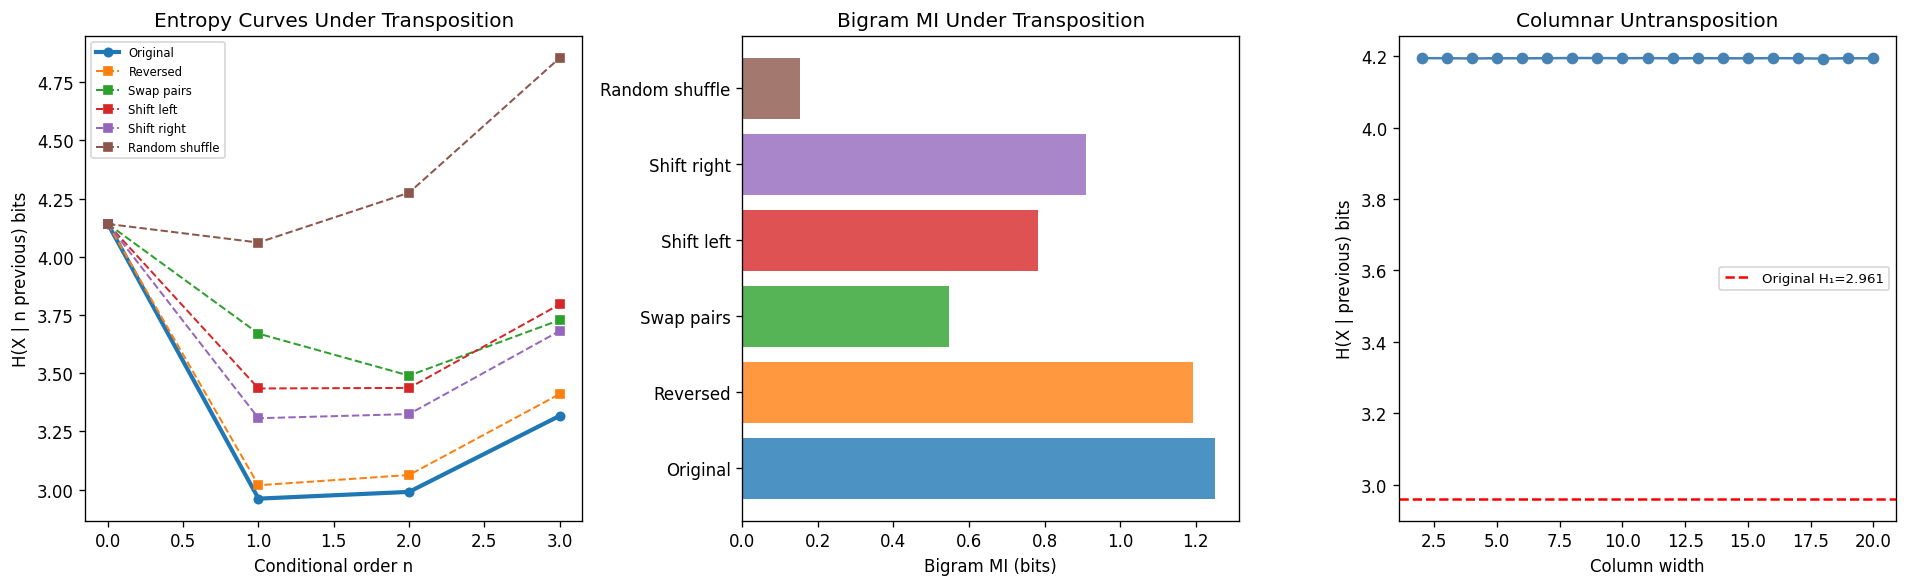

Saved: images/cipher_transposition.png

=== INTERPRETATION ===
Original H₁: 2.9608
Best word-level scheme: Original → H₁=2.9608 (Δ=+0.0000)
Best columnar width: 18 → H₁=4.1934 (Δ=+1.2326)
→ No scheme significantly improves entropy → INCONSISTENT with transposition cipher
→ The original glyph order already has maximal bigram structure


In [6]:
def entropia_condicional_n(corpus_plano, n, max_tokens=500000):
    """H(token | n previous tokens) with Witten-Bell smoothing."""
    corpus = corpus_plano[:max_tokens]
    vocab = sorted(set(corpus))
    V = len(vocab)
    if n == 0:
        freq = Counter(corpus)
        total = len(corpus)
        return -sum((c / total) * math.log2(c / total) for c in freq.values())
    ngram_counts = Counter()
    nplus1_counts = Counter()
    for i in range(len(corpus) - n):
        ctx = tuple(corpus[i:i + n])
        next_tok = corpus[i + n]
        ngram_counts[ctx] += 1
        nplus1_counts[(ctx, next_tok)] += 1
    ctx_types = Counter()
    for (ctx_key, _) in nplus1_counts:
        ctx_types[ctx_key] += 1
    total_ctx = sum(ngram_counts.values())
    H = 0.0
    for ctx, ctx_count in ngram_counts.items():
        p_ctx = ctx_count / total_ctx
        tipos_ctx = ctx_types[ctx]
        denom = ctx_count + tipos_ctx
        if denom == 0:
            continue
        H_ctx = 0.0
        for tok in vocab:
            c = nplus1_counts.get((ctx, tok), 0)
            if c > 0:
                p = c / denom
            else:
                p = (tipos_ctx / denom) / V if V > 0 else 0
            if p > 0:
                H_ctx -= p * math.log2(p)
        H += p_ctx * H_ctx
    return H

# ── Define transposition schemes ──
def apply_transposition(palabras, scheme):
    """Apply a transposition scheme to each word and return flat corpus."""
    result = []
    for w in palabras:
        if scheme == 'original':
            result.extend(w)
        elif scheme == 'reverse':
            result.extend(w[::-1])
        elif scheme == 'swap_pairs':
            new_w = list(w)
            for i in range(0, len(new_w) - 1, 2):
                new_w[i], new_w[i+1] = new_w[i+1], new_w[i]
            result.extend(new_w)
        elif scheme == 'shift_left':
            if len(w) > 1:
                result.extend(w[1:] + [w[0]])
            else:
                result.extend(w)
        elif scheme == 'shift_right':
            if len(w) > 1:
                result.extend([w[-1]] + w[:-1])
            else:
                result.extend(w)
        elif scheme == 'random':
            shuffled_w = list(w)
            random.shuffle(shuffled_w)
            result.extend(shuffled_w)
    return result

# ── Compute conditional entropy curves for each scheme ──
schemes = ['original', 'reverse', 'swap_pairs', 'shift_left', 'shift_right', 'random']
scheme_labels = ['Original', 'Reversed', 'Swap pairs', 'Shift left', 'Shift right', 'Random shuffle']
orders = [0, 1, 2, 3]

print("=== TRANSPOSITION TEST ===")
print(f"Computing conditional entropy H(X|context) for orders 0-3...\n")

entropy_results = {}
for scheme, label in zip(schemes, scheme_labels):
    corpus_t = apply_transposition(palabras, scheme)
    H_curve = [entropia_condicional_n(corpus_t, n) for n in orders]
    entropy_results[label] = H_curve
    print(f"  {label:15s}: H = {[f'{h:.3f}' for h in H_curve]}")

# ── Also compute MI for each scheme ──
print(f"\nBigram MI per scheme:")
mi_results = {}
for scheme, label in zip(schemes, scheme_labels):
    corpus_t = apply_transposition(palabras, scheme)
    mi = bigram_mutual_information(corpus_t)
    mi_results[label] = mi
    print(f"  {label:15s}: MI = {mi:.4f} bits")

# ── Columnar transposition test ──
print(f"\n=== Columnar Transposition (block-level) ===")
# Treat corpus as a flat stream, read into columns of width w, then read by rows
def columnar_untranspose(sequence, width):
    """Undo columnar transposition with given width."""
    n = len(sequence)
    n_full_cols = n % width
    col_height = n // width
    # Build columns
    result = []
    cols = []
    idx = 0
    for c in range(width):
        h = col_height + (1 if c < n_full_cols else 0)
        cols.append(sequence[idx:idx+h])
        idx += h
    # Read by rows
    for r in range(col_height + 1):
        for c in range(width):
            if r < len(cols[c]):
                result.append(cols[c][r])
    return result

col_results = {}
for w in range(2, 21):
    untransposed = columnar_untranspose(corpus_plano, w)
    H1 = entropia_condicional_n(untransposed, 1)
    col_results[w] = H1

print(f"{'Width':>6} {'H(X|prev)':>10}")
for w in sorted(col_results):
    marker = " ←" if col_results[w] < entropy_results['Original'][1] - 0.05 else ""
    print(f"  {w:4d}   {col_results[w]:.4f}{marker}")

# ── Visualization ──
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Left: entropy curves
colors_scheme = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
for (label, H_curve), color in zip(entropy_results.items(), colors_scheme):
    style = '-o' if label == 'Original' else '--s'
    lw = 2.5 if label == 'Original' else 1.2
    axes[0].plot(orders, H_curve, style, label=label, color=color, lw=lw, markersize=5)
axes[0].set_xlabel('Conditional order n')
axes[0].set_ylabel('H(X | n previous) bits')
axes[0].set_title('Entropy Curves Under Transposition')
axes[0].legend(fontsize=7)

# Middle: MI comparison
labels_mi = list(mi_results.keys())
values_mi = list(mi_results.values())
axes[1].barh(labels_mi, values_mi, color=colors_scheme[:len(labels_mi)], alpha=0.8)
axes[1].set_xlabel('Bigram MI (bits)')
axes[1].set_title('Bigram MI Under Transposition')

# Right: columnar H(X|1) by width
widths = sorted(col_results.keys())
h_vals = [col_results[w] for w in widths]
axes[2].plot(widths, h_vals, '-o', color='steelblue')
axes[2].axhline(entropy_results['Original'][1], color='red', ls='--',
                label=f"Original H₁={entropy_results['Original'][1]:.3f}")
axes[2].set_xlabel('Column width')
axes[2].set_ylabel('H(X | previous) bits')
axes[2].set_title('Columnar Untransposition')
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig('images/cipher_transposition.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: images/cipher_transposition.png")

# ── Interpretation ──
print(f"\n=== INTERPRETATION ===")
orig_H1 = entropy_results['Original'][1]
best_scheme = min(entropy_results, key=lambda k: entropy_results[k][1])
best_H1 = entropy_results[best_scheme][1]
best_col_w = min(col_results, key=col_results.get)
best_col_H1 = col_results[best_col_w]

print(f"Original H₁: {orig_H1:.4f}")
print(f"Best word-level scheme: {best_scheme} → H₁={best_H1:.4f} (Δ={best_H1 - orig_H1:+.4f})")
print(f"Best columnar width: {best_col_w} → H₁={best_col_H1:.4f} (Δ={best_col_H1 - orig_H1:+.4f})")

if best_H1 < orig_H1 - 0.05 or best_col_H1 < orig_H1 - 0.05:
    print("→ Some transposition scheme IMPROVES entropy → possible transposition component!")
else:
    print("→ No scheme significantly improves entropy → INCONSISTENT with transposition cipher")
    print("→ The original glyph order already has maximal bigram structure")

## Summary and Discussion

### The Central Paradox

The four diagnostic tests unanimously indicate that the Voynich text behaves statistically
like **natural language or simple monoalphabetic substitution**:

- IC is 12.7× above random (polyalphabetic discarded)
- No periodic key signature (Vigenère/Alberti discarded)
- Strong bigram structure preserved (polygraphic discarded)
- Original glyph order is already optimal (transposition discarded)

Yet **16 monoalphabetic decipherment models** across 6 languages could not crack it
(ceiling: 68% n-gram, 3 roots). This contradiction narrows the viable explanations to:

1. **Monoalphabetic substitution to an untested language** — but we covered Hebrew, Aramaic,
   Arabic, Latin (biblical and mishnic registers), and the inter-language gap is small
2. **Nomenclator** — a mix of substitution cipher + code symbols for common words.
   Statistically indistinguishable from natural language, and the dominant diplomatic cipher
   in 15th-century Italy. The 166 glyph types could include both letter-substitutions and
   word-codes, explaining why pure character-level models hit a ceiling
3. **Constructed or artificial language** — an invented grammar with natural-language-like
   statistics but no underlying real language. Compatible with the Cardan grille hypothesis
   (Rugg 2004) or glossolalia
4. **Meaningful text in a genuine but rare language** — one not represented in our test
   corpora (e.g., a Turkic, Romani, or Southeast Asian language)

The nomenclator hypothesis is particularly interesting because it would explain both the
natural-language statistics AND the failure of pure substitution: some glyphs encode letters
while others encode entire words or syllables, making character-level models fundamentally
incomplete.

In [7]:
print("=" * 70)
print("CIPHER-TYPE DIAGNOSTIC SUMMARY")
print("=" * 70)

# ── Collect results ──
summary = {
    'test1_ic': {
        'voynich_ic': round(ic_voynich, 6),
        'random_ic': round(ic_random, 6),
        'ic_ratio': round(ic_voynich / ic_random, 2),
        'ic_onset': round(ic_onset, 6),
        'ic_middle': round(ic_middle, 6),
        'ic_coda': round(ic_coda, 6),
        'verdict': 'NOT polyalphabetic' if ic_voynich > 3 * ic_random else 'Possibly polyalphabetic'
    },
    'test2_kasiski': {
        'trigram_repeated': len(kasiski_results[3]),
        'max_factor_enrichment': round(max(enrichments_3), 2),
        'verdict': 'NO periodic key detected' if max(enrichments_3) < 1.5 else f'Possible key period detected'
    },
    'test3_bigram': {
        'unigram_entropy': round(H1_voynich, 4),
        'bigram_entropy': round(H2_voynich, 4),
        'mutual_information': round(MI_voynich, 4),
        'mi_normalized': round(MI_norm, 4),
        'mi_z_score': round(mi_z, 1),
        'chi2_ratio': round(chi2_ratio, 2),
        'verdict': 'NOT polygraphic' if MI_norm > 0.10 else 'Possibly polygraphic'
    },
    'test4_transposition': {
        'original_H1': round(orig_H1, 4),
        'best_scheme': best_scheme,
        'best_H1': round(best_H1, 4),
        'best_columnar_width': best_col_w,
        'best_columnar_H1': round(best_col_H1, 4),
        'verdict': 'NO transposition detected' if (best_H1 >= orig_H1 - 0.05 and best_col_H1 >= orig_H1 - 0.05) else 'Possible transposition'
    }
}

# ── Scorecard ──
print()
tests = [
    ('1. Index of Coincidence', summary['test1_ic']['verdict'],
     f"IC={summary['test1_ic']['voynich_ic']:.4f}, {summary['test1_ic']['ic_ratio']}× random"),
    ('2. Kasiski Examination', summary['test2_kasiski']['verdict'],
     f"max enrichment={summary['test2_kasiski']['max_factor_enrichment']}×"),
    ('3. Bigram Entropy', summary['test3_bigram']['verdict'],
     f"MI_norm={summary['test3_bigram']['mi_normalized']}, z={summary['test3_bigram']['mi_z_score']}"),
    ('4. Transposition Test', summary['test4_transposition']['verdict'],
     f"best ΔH₁={summary['test4_transposition']['best_H1'] - summary['test4_transposition']['original_H1']:+.4f}"),
]

for name, verdict, detail in tests:
    marker = "✗" if "NOT" in verdict or "NO " in verdict else "?"
    print(f"  {marker} {name:30s}: {verdict}")
    print(f"    {detail}")
    print()

# ── Overall conclusion ──
print("=" * 70)
print("OVERALL CONCLUSION:")
print("=" * 70)
n_discarded = sum(1 for _, v, _ in tests if "NOT" in v or "NO " in v)
print(f"\n  {n_discarded}/4 alternative cipher types DISCARDED:")
print()
discarded_types = []
if 'NOT' in summary['test1_ic']['verdict']:
    discarded_types.append('Polyalphabetic (Vigenère/Alberti)')
    print("  • Polyalphabetic: IC is far above random, no periodic key signature")
if 'NO' in summary['test2_kasiski']['verdict']:
    discarded_types.append('Periodic-key cipher')
    print("  • Periodic key: No factor enrichment in Kasiski distances")
if 'NOT' in summary['test3_bigram']['verdict']:
    discarded_types.append('Polygraphic (Playfair/Hill)')
    print("  • Polygraphic: Strong bigram structure preserved (MI well above null)")
if 'NO' in summary['test4_transposition']['verdict']:
    discarded_types.append('Transposition cipher')
    print("  • Transposition: No reordering scheme improves entropy structure")

print(f"\n  Remaining viable cipher types:")
print("  • Simple substitution (monoalphabetic) — already tested in 16 models")
print("  • Nomenclator (substitution + code words) — cannot be distinguished")
print("    from natural language statistics alone")
print("  • Constructed/artificial language — IC and structure are language-like")

# ── Export ──
output = {
    'notebook': '29_cipher_diagnostics',
    'corpus': {'glyphs': len(corpus_plano), 'words': len(palabras), 'vocab': len(VOCAB)},
    'tests': summary,
    'discarded_types': discarded_types,
    'remaining_types': ['monoalphabetic substitution', 'nomenclator', 'constructed language'],
    'conclusion': f'{n_discarded}/4 alternative cipher types discarded'
}

with open('cipher_diagnostics_resultados.json', 'w') as f:
    json.dump(output, f, indent=2, ensure_ascii=False)
print(f"\nSaved: cipher_diagnostics_results.json")

CIPHER-TYPE DIAGNOSTIC SUMMARY

  ✗ 1. Index of Coincidence       : NOT polyalphabetic
    IC=0.0764, 12.68× random

  ✗ 2. Kasiski Examination        : NO periodic key detected
    max enrichment=1.0×

  ✗ 3. Bigram Entropy             : NOT polygraphic
    MI_norm=0.3024, z=3831.2

  ✗ 4. Transposition Test         : NO transposition detected
    best ΔH₁=+0.0000

OVERALL CONCLUSION:

  4/4 alternative cipher types DISCARDED:

  • Polyalphabetic: IC is far above random, no periodic key signature
  • Periodic key: No factor enrichment in Kasiski distances
  • Polygraphic: Strong bigram structure preserved (MI well above null)
  • Transposition: No reordering scheme improves entropy structure

  Remaining viable cipher types:
  • Simple substitution (monoalphabetic) — already tested in 16 models
  • Nomenclator (substitution + code words) — cannot be distinguished
    from natural language statistics alone
  • Constructed/artificial language — IC and structure are language-like

Saved: